# Reconhecimento de Padrões em Fluxos de Rede Através de Aprendizado Não Supervisionado

**Autor:** Richard Nozari Cassol Lahm Piccoli  
**Data:** outubro de 2026


Imports e Configuração Inicial

In [1]:
# ============================================================
# Reconhecimento de Padrões em Fluxos de Rede
# Através de Aprendizado Não Supervisionado
# ============================================================
# Autor: Richard Nozari Cassol Lahm Piccoli
# Data: outubro de 2026
# ------------------------------------------------------------
# Notebook com visualizações, experimentos e teoria
# ============================================================

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

sns.set(style="whitegrid")
RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

print("Notebook carregado com sucesso!")

Notebook carregado com sucesso!


Carregamento do Dataset e Preparação

In [2]:
# ============================================================
# 1. Carregamento e Pré-processamento
# ============================================================
# Nesta etapa, preparamos os dados e criamos a matriz X que
# será fatorada pelo PCA
# ============================================================

import os

# Partição de TREINO do UNSW-NB15 (175.341 linhas).
# Atenção: no download oficial os nomes dos arquivos vêm trocados; o arquivo
# de treino correto é o que tem 175.341 linhas.
CANDIDATE_PATHS = [
    "data/UNSW_NB15_training-set.csv",      # repositório clonado / execução local
    "/content/UNSW_NB15_training-set.csv",  # upload manual no Colab
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset UNSW_NB15_training-set.csv não encontrado. "
        "Coloque o arquivo em data/ (ou faça upload em /content no Colab)."
    )

df = pd.read_csv(DATA_PATH)
print(f"Dataset carregado de {DATA_PATH}: {len(df)} linhas")
if len(df) != 175341:
    print("Aviso: a partição de treino tem 175.341 linhas; confira se o arquivo é o correto.")

# Seleção de variáveis numéricas relevantes
NUMERIC_CANDIDATES = [
    'dur','sbytes','dbytes','spkts','dpkts','swin','dwin',
    'sttl','dttl','sload','dload','ct_state_ttl'
]

features = [c for c in NUMERIC_CANDIDATES if c in df.columns]
X = df[features].fillna(0).copy()

# Feature Engineering simples
if 'sbytes' in X and 'dbytes' in X:
    X['bytes_total'] = X['sbytes'] + X['dbytes']
if 'spkts' in X and 'dpkts' in X:
    X['pkts'] = X['spkts'] + X['dpkts']
if 'dur' in X:
    X['pkt_rate']  = X['pkts'] / (X['dur'] + 1e-6)
    X['byte_rate'] = X['bytes_total'] / (X['dur'] + 1e-6)

# Padronização é essencial para PCA e KMeans (distância euclidiana)
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

# Labels (0=normal, 1=ataque)
y_true = df['label'].values if 'label' in df else None

print("Matriz final Xs com shape:", Xs.shape)

Dataset carregado de data/UNSW_NB15_training-set.csv: 175341 linhas


Matriz final Xs com shape: (175341, 16)


Funções Matemáticas (Vetorizadas e Comentadas)

In [3]:
# ============================================================
# 2. Funções Matemáticas
# ============================================================
# Aqui usamos PCA como fatoração SVD truncada.
# Usamos K-Means conforme Teorema do centróide ótimo.
# ============================================================

def calculate_reconstruction_losses(X_matrix, pca_model):
    """
    Cálculo vetorizado do erro de reconstrução.

    Teoria:
    -------
    O PCA aproxima X ≈ U_k Σ_k V_k^T, reduzindo posto.
    O erro ||X - X_hat|| mede o quanto o ponto está fora
    do subespaço principal.

    A_k é a melhor aproximação de posto k na norma Frobenius.
    """
    Z = pca_model.transform(X_matrix)
    X_hat = pca_model.inverse_transform(Z)
    losses = np.linalg.norm(X_matrix - X_hat, axis=1)
    return losses

def calculate_kmeans_distances(Z_matrix, kmeans_model):
    """
    Distância do ponto ao centróide atribuído.

    Teoria:
    -------
    Pelo Teorema do centróide ótimo, o melhor representante do cluster
    é a média (centróide). Quanto mais distante do centro,
    mais outlier o ponto tende a ser.
    """
    centers = kmeans_model.cluster_centers_
    labels = kmeans_model.labels_
    assigned = centers[labels]
    dists = np.linalg.norm(Z_matrix - assigned, axis=1)
    return dists

def get_metrics(y_true, y_pred):
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1, zero_division=0
    )
    return prec, rec, f1

Gráficos (todos integrados e prontos)

In [4]:
# ============================================================
# 3. Conjunto Completo de Gráficos
# ============================================================

def plot_scree(pca):
    """Gráfico da variância explicada por componente (Scree Plot)."""
    plt.figure(figsize=(8,5))
    plt.plot(np.arange(1, len(pca.explained_variance_ratio_) + 1),
             pca.explained_variance_ratio_, marker='o')
    plt.title("Scree Plot — Variância Explicada por Componente")
    plt.xlabel("Componente Principal")
    plt.ylabel("Variância Explicada")
    plt.grid()
    plt.show()

def plot_pca_2d(Z, y):
    """Projeção PCA 2D colorida por rótulo."""
    plt.figure(figsize=(8,6))
    plt.scatter(Z[:,0], Z[:,1], c=y, cmap="coolwarm", s=10)
    plt.title("Projeção PCA (2 Componentes)")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.colorbar(label="Label (0=Normal, 1=Attack)")
    plt.show()

def plot_reconstruction_distribution(errs):
    """Distribuição do erro de reconstrução."""
    plt.figure(figsize=(8,5))
    sns.histplot(errs, bins=40, kde=True)
    plt.title("Distribuição do Erro de Reconstrução")
    plt.xlabel("Erro ||x - x_hat||")
    plt.show()

def plot_threshold(errs, thr):
    """Histograma com threshold marcado."""
    plt.figure(figsize=(8,5))
    sns.histplot(errs, bins=40, kde=True)
    plt.axvline(thr, color='red', linestyle='--', label=f"Threshold={thr:.4f}")
    plt.legend()
    plt.title("Threshold aplicado no Erro de Reconstrução")
    plt.show()

def plot_kmeans_clusters(Z, km):
    """Visualização dos clusters K-Means no espaço PCA."""
    lbl = km.labels_
    centers = km.cluster_centers_
    plt.figure(figsize=(8,6))
    plt.scatter(Z[:,0], Z[:,1], c=lbl, cmap="viridis", s=8)
    plt.scatter(centers[:,0], centers[:,1], c="red", s=120, marker="X")
    plt.title("Clusters K-Means no Espaço PCA")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.show()

def plot_confusion(y_true, y_pred):
    """Heatmap da matriz de confusão."""
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, cmap="Blues", fmt="d")
    plt.title("Matriz de Confusão")
    plt.xlabel("Predito")
    plt.ylabel("Verdadeiro")
    plt.show()

def plot_heatmap_results(results_df, metric="f1_recon"):
    """Heatmap das métricas obtidas nos experimentos."""
    pivot = results_df.pivot_table(index="pca_dim",
                                   columns="threshold_pct",
                                   values=metric,
                                   aggfunc="mean")
    plt.figure(figsize=(8,6))
    sns.heatmap(pivot, annot=True, cmap="viridis")
    plt.title(f"Heatmap da Métrica {metric}")
    plt.show()

Loop Completo de Experimentos

In [5]:
# ============================================================
# 4. Loop Completo de Experimentos
# ============================================================

PCA_COMPONENTS = [2, 5, 10, 12]
K_VALUES = [2, 3, 5]
THRESHOLDS = [90, 95, 99]

results = []

print("Executando experimentos...")

# bytes_total e pkts são combinações lineares de outras colunas, então o
# posto de Xs é menor que o número de colunas. Com k >= posto o PCA reconstrói
# tudo exatamente (erro ~1e-15, só ruído numérico), então esses k são ignorados.
rank_X = np.linalg.matrix_rank(Xs)
print("Posto de Xs:", rank_X)

for n_comp in PCA_COMPONENTS:
    if n_comp >= rank_X:
        print(f"pca_dim={n_comp} ignorado (>= posto {rank_X})")
        continue
    n_eff = n_comp

    pca = PCA(n_components=n_eff, random_state=RANDOM_STATE)
    pca.fit(Xs)

    Z = pca.transform(Xs)
    recon_errors = calculate_reconstruction_losses(Xs, pca)

    for k in K_VALUES:
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        km.fit(Z)
        dists = calculate_kmeans_distances(Z, km)

        for thr in THRESHOLDS:

            thr_recon = np.percentile(recon_errors, thr)
            thr_km = np.percentile(dists, thr)

            pred_recon = (recon_errors > thr_recon).astype(int)
            pred_km    = (dists > thr_km).astype(int)

            if y_true is not None:
                p_r, r_r, f1_r = get_metrics(y_true, pred_recon)
                p_k, r_k, f1_k = get_metrics(y_true, pred_km)
            else:
                p_r = r_r = f1_r = p_k = r_k = f1_k = None

            results.append({
                'pca_dim': n_eff,
                'k_clusters': k,
                'threshold_pct': thr,
                'prec_recon': p_r, 'rec_recon': r_r, 'f1_recon': f1_r,
                'prec_kmeans': p_k, 'rec_kmeans': r_k, 'f1_kmeans': f1_k
            })

results_df = pd.DataFrame(results)
results_df.to_csv("tabela_experimentos.csv", index=False)

print("Experimentos concluídos!")
results_df.head()

Executando experimentos...
Posto de Xs: 14


Experimentos concluídos!


,pca_dim,k_clusters,threshold_pct,prec_recon,rec_recon,f1_recon,prec_kmeans,rec_kmeans,f1_kmeans
0,2,2,90,0.345557,0.050770,0.088533,0.458176,0.067194,0.117200
1,2,2,95,0.408007,0.029973,0.055844,0.681424,0.045399,0.085127
2,2,2,99,0.841834,0.012309,0.024264,0.436146,0.006410,0.012635
3,2,3,90,0.345557,0.050770,0.088533,0.475609,0.069850,0.121811
4,2,3,95,0.408007,0.029973,0.055844,0.681773,0.045634,0.085542


Gráficos Automáticos da Melhor Configuração

Melhor configuração detectada:
 pca_dim          10.000000
k_clusters        3.000000
threshold_pct    90.000000
prec_recon        0.435326
rec_recon         0.063960
f1_recon          0.111532
prec_kmeans       0.365518
rec_kmeans        0.053703
f1_kmeans         0.093647
Name: 21, dtype: float64


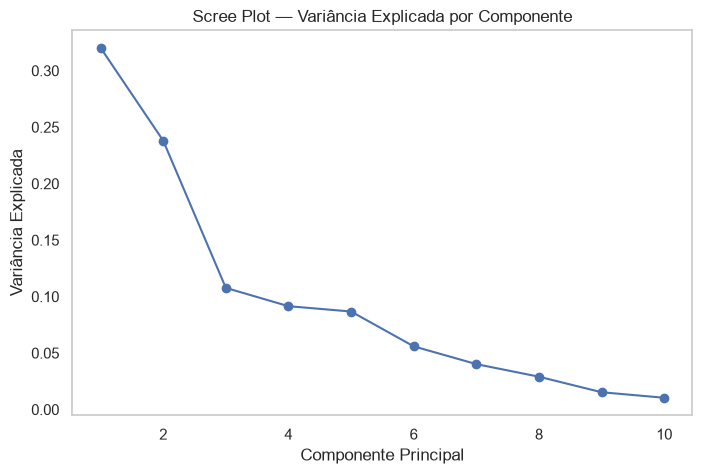

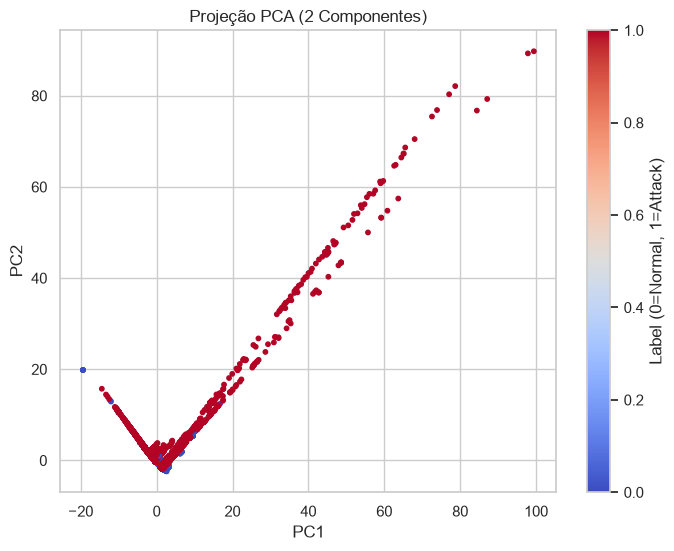

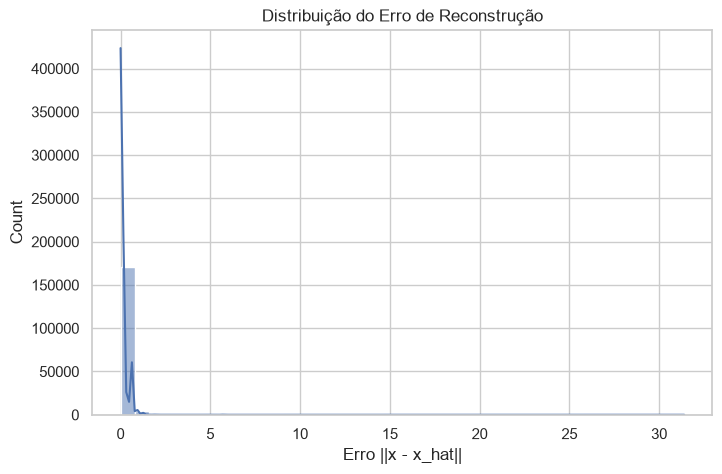

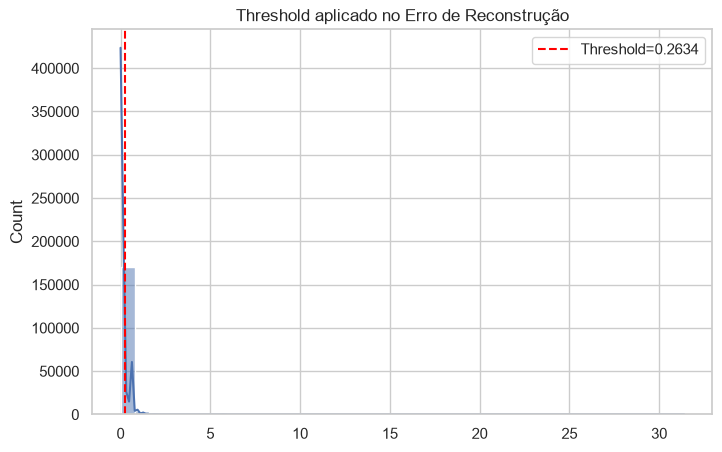

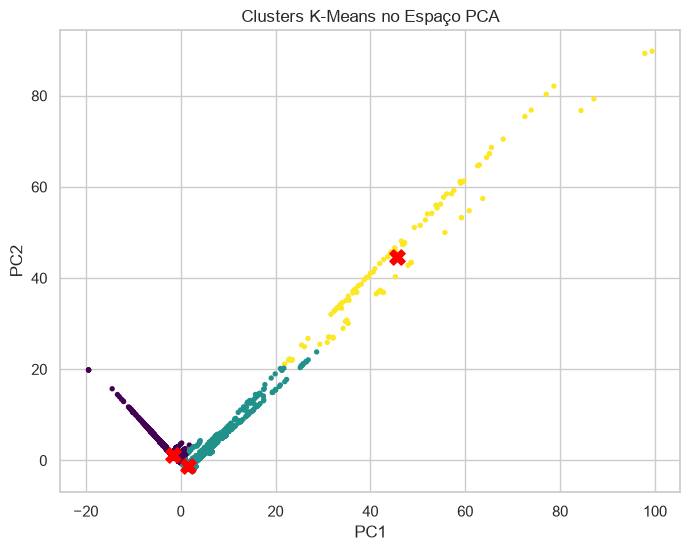

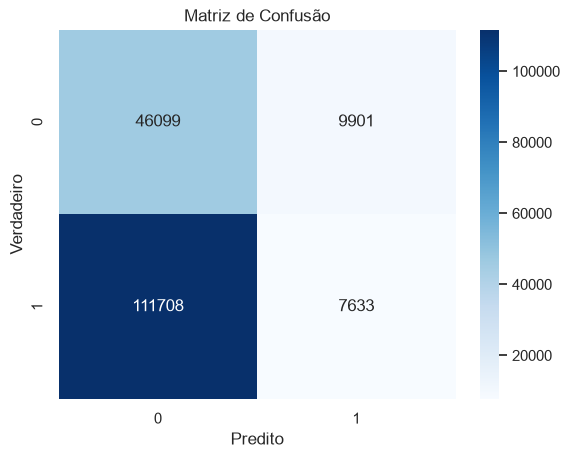

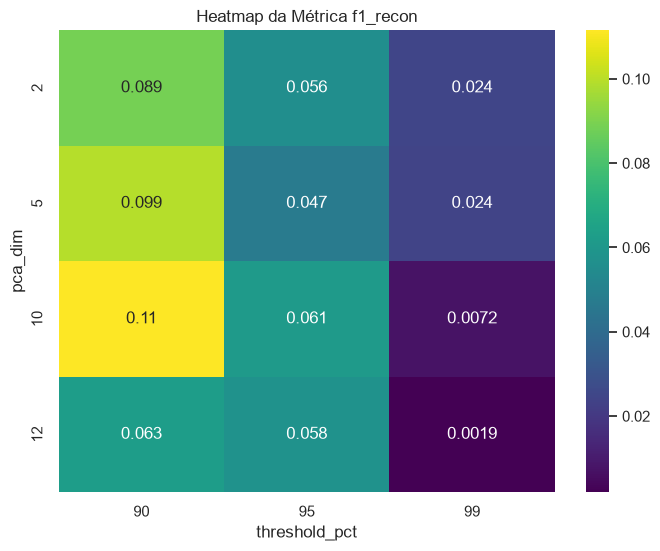

In [6]:
# ============================================================
# 5. Encontrando a melhor configuração (F1 Reconstrução)
# ============================================================

if y_true is not None:
    best = results_df.sort_values(by="f1_recon", ascending=False).iloc[0]
    print("Melhor configuração detectada:\n", best)

    # Reprocessar melhor configuração
    n_eff = int(best['pca_dim'])
    k = int(best['k_clusters'])
    thr = best['threshold_pct']

    # PCA novamente
    pca = PCA(n_components=n_eff, random_state=RANDOM_STATE)
    Z = pca.fit_transform(Xs)
    recon_errors = calculate_reconstruction_losses(Xs, pca)

    # Threshold real
    thr_val = np.percentile(recon_errors, thr)
    pred = (recon_errors > thr_val).astype(int)

    # Plotar gráficos explicativos
    plot_scree(pca)
    plot_pca_2d(Z, y_true)
    plot_reconstruction_distribution(recon_errors)
    plot_threshold(recon_errors, thr_val)

    # K-Means para visualização
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(Z)
    plot_kmeans_clusters(Z, km)

    # Matriz de confusão
    plot_confusion(y_true, pred)

    # Heatmap geral dos resultados
    plot_heatmap_results(results_df, metric="f1_recon")

else:
    print("Sem labels → gráficos supervisionados desativados.")